# Project 7

In addition to answering the bolded questions on Coursera, also attach your notebook, both as
`.ipynb` and `.html`.

A hospital in Philadelphia is trying to better streamline its operations and plan for the future by reducing the number hospitalizations that could have been prevented. They have approached you, a data scientist, to help predict if patients will develop heart diseases so that healthcare providers have a chance to intervene much earlier. For this task, you have been provided with the Heart dataset, containing a binary outcome 'HD' that indicates the presence of heart disease in 303 patients. There are 13 predictors including 'Age', 'Sex', 'Chol' (a cholesterol measurement), and other heart and lung function measurements.


In this version of the assignment, the original PennGrader checks have been replaced with local notebook checks for immediate feedback. Official scoring is performed in Gradescope using hidden tests. The assignment questions, variable names, model specifications, and notebook flow are otherwise preserved.

<b>NOTE：Please remember to remove the </b>

```python
raise notImplementedError
```
<b>after your implementation, otherwise the cell will not compile.</b>


## How this notebook is graded

Read this section before you start. Most points lost on this project come from
these rules, not from the machine learning.

**What you submit.** At the end you convert this notebook to
`project7_submission.py` and upload that file to Gradescope. Gradescope runs 20
tests worth 1 point each; the table below lists them. The questions keep their
original numbers (there is no question 5), so they line up with the quiz.

**Notes for Gradescope.** Under each graded question there's a numbered list
headed *Notes for Gradescope*. The question tells you what to do; the notes tell
you how Gradescope checks it:

- the variable your answer must be stored in;
- settings that must be exact, such as `random_state=42`, a search grid or
  `cv=10`;
- mistakes that cost the point even though your notebook looks right;
- what to do instead, where an older instruction in the question (such as the
  Codio steps) no longer applies.

Read the notes before you write the cell. When a public check fails, the fix is
usually in that question's notes.

**How Gradescope runs your code.** Gradescope doesn't run your notebook from top
to bottom. It runs each graded cell by itself, in a fresh Python session, on its
own hidden copy of the data. Before running a cell, it loads the setup imports
and the results of the earlier questions that the cell needs, for example
`heart` for question 3, or the four split variables for the model questions.
So:

- Use only those, plus what the cell defines itself. A helper function or a
  variable from an ungraded cell doesn't exist on Gradescope, so the cell fails
  there with a `NameError`, even though it runs in your notebook. Where a cell
  gets less than you might expect, its notes say so.
- Compute every answer with code. Don't type in numbers or column names you
  read off your output; on the hidden data they're different. The
  multiple-choice answers are the only exception.
- The setup imports are `pd`, `np`, `tree`, `DecisionTreeClassifier`,
  `BaggingClassifier`, `RandomForestClassifier`, `train_test_split`,
  `GridSearchCV`, `precision_score`, `recall_score`, `accuracy_score`, `Image`
  and `pydotplus`. Nothing else is loaded, so don't use `f1_score`,
  `confusion_matrix`, `plt` or `sns` in a graded cell.
- Don't write `import` lines in graded cells. Gradescope swaps in a faster
  `GridSearchCV`, and importing `GridSearchCV` yourself undoes that, so the test
  fails. `seaborn`, `matplotlib`, `graphviz` and `pydot` aren't installed on
  Gradescope at all.
- Don't use `display()` in graded cells. Use `print()`.
- Keep plots and exploration in ungraded cells.
- Don't add notebook commands (lines starting with `%` or `!`, such as
  `!pip install`) **anywhere** in the notebook. Depending on how the notebook
  is converted, such a line can make the whole `.py` file invalid Python, and
  Gradescope then gives 0 for every test.

**Graded cells.** Each graded cell starts with a tag line beginning with
`# PROJECT7_TASK`, followed by a `# Define:` line that names the variables
Gradescope reads.

- Write your answer under these lines and delete the `raise NotImplementedError`
  line.
- Don't change, move or copy the tag line, and don't split the cell or merge it
  with another cell.
- Right after each graded cell comes its public-check cell, whose first line
  starts with `# In[ ]:`. Keep that line, and don't insert cells between a
  graded cell and its check cell: Gradescope uses that line to find where your
  answer ends.

**Public checks.** After each graded cell there's a cell that runs a check from
`public_checks.py`. It looks at your results on the real `Heart.csv` and tests
what Gradescope tests: variable names and types, settings such as
`random_state=42` and `cv=10`, the exact search grids, and whether your metrics
match your model. If a check fails, it lists what to fix; fix it before moving
on. For the three multiple-choice questions, the checks look only at the format
of your answer, not whether it's right.

**Before you submit.** The last section converts the notebook and runs
`public_checks.check_submission_file()`, which reads the converted file the way
Gradescope does and reports problems such as names from other cells or imports
in graded cells.

### The 20 Gradescope tests

| Question | What it grades | Variables | Points |
|---|---|---|---|
| 1 | Load and clean the data | `heart` | 1 |
| 2 | Encode `HD`, `ChestPain` and `Thal` | `heart` | 1 |
| 3 | Minimum and maximum age | `min_age`, `max_age` | 1 |
| 4 | Highest positive correlation with `HD` | `highest_corr` | 1 |
| 6 | Train/test split | `X_train`, `X_test`, `y_train`, `y_test` | 1 |
| Part A, 1 | Base decision tree | `clf` | 1 |
| Part A, 2 | Tree plot | `img` | 1 |
| Part A, 3 | Base tree metrics | `dt_precision`, `dt_recall`, `dt_accuracy` | 1 |
| Part A, 4a | Multiple choice: what to tune | `answers` | 1 |
| Part A, 4b | Tuned decision tree and its metrics | `grid_search_cv_dt`, `dt_tuned_precision`, `dt_tuned_recall`, `dt_tuned_accuracy` | 1 |
| Part B, 1 | Base bagging model | `bag` | 1 |
| Part B, 2 | Base bagging metrics | `bag_precision`, `bag_recall`, `bag_accuracy` | 1 |
| Part B, 3 | Tuned bagging model and its metrics | `grid_search_cv_bag`, `bag_tuned_precision`, `bag_tuned_recall`, `bag_tuned_accuracy` | 1 |
| Part B, 3 | Best bagging hyperparameters | `bag_best_param` | 1 |
| Part C, 1 | Base random forest | `rf` | 1 |
| Part C, 2 | Base forest metrics | `rf_precision`, `rf_recall`, `rf_accuracy` | 1 |
| Part C, 3 | Tuned random forest and its metrics | `grid_search_cv_rf`, `rf_tuned_precision`, `rf_tuned_recall`, `rf_tuned_accuracy` | 1 |
| Part C, 3 | Best forest hyperparameters | `rf_tuned` | 1 |
| 10 | Multiple choice: best base model | `choice` | 1 |
| 11 | Multiple choice: best tuned model | `choice` | 1 |
|  | **Total** |  | **20** |

## Getting Set Up
Enter your Student ID and name below for your notebook record. Gradescope identifies your submitted file separately.


You also need two files in the same folder as this notebook:

- `Heart.csv`, the data;
- `public_checks.py`, the public checks.

On Google Colab, upload both with the **Files** panel on the left (folder icon,
then the upload button). Colab deletes uploaded files when the runtime
restarts, so upload them again after a restart.

Run the next three cells in order. The first one installs `pydotplus`, which
Part A question 2 needs to draw the tree.

In [1]:
# Installs pydotplus for the tree plot in Part A, question 2.
# Colab already has the Graphviz program. On your own computer you also need it:
#   conda install graphviz      (or, on macOS: brew install graphviz)
# Plain Python instead of "%pip install": a % or ! line is not valid Python, so
# some ways of converting the notebook to .py would make Gradescope reject the file.
import subprocess
import sys

try:
    import pydotplus
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pydotplus"], check=True)

In [2]:
# Data handling
import numpy as np
import pandas as pd

# Plotting (use these in ungraded cells only)
import matplotlib.pyplot as plt
import seaborn as sns
import pydotplus
from IPython.display import Image

# Models, tuning and metrics
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score,
    confusion_matrix,
)

# Public checks: public_checks.py must be in the same folder as this notebook
import public_checks

In [3]:
#PLEASE ENSURE YOUR STUDENT ID AND NAME ARE ENTERED CORRECTLY

STUDENT_ID = 27435656           # YOUR STUDENT ID GOES HERE
STUDENT_NAME = "Fuad Hassan"      # YOUR FULL NAME GOES HERE

Now we are ready for this project. Before building our models, let's take a look at how the data looks like.
1. Load the Heart data and drop any rows with `NaN/null` values.

*Notes for Gradescope*:

1. Store the data in `heart`. Read it with `pd.read_csv("Heart.csv")`: exactly this file name, with no folder in front of it and no `index_col`. Gradescope supplies its own `Heart.csv` under that name.
2. Drop every row that has at least one missing value.
3. On the real data you should get 297 rows and 14 columns (6 of the 303 rows have a missing value).

In [4]:
# PROJECT7_TASK:read_data
# Define: heart
heart = pd.read_csv("Heart.csv")
heart = heart.dropna()

In [5]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_read_data(heart)

[PASS] read_data


True

In [6]:
heart.head()

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,HD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No


2. Binarize the 'HD' values such that `No=0` and `Yes=1`. One hot encode categorical features, and set prefixes to original column names. Produce some numerical and graphical summaries of it. Do there appear to be any patterns? 

Hint: Don't forget to drop original columns after one hot encode.

The order of your columns should be as follows:  

* Age	
* Sex	
* RestBP	
* Chol	
* Fbs
* RestECG
* MaxHR
* ExAng
* Oldpeak
* Slope
* Ca
* HD
* ChestPain_asymptomatic
* ChestPain_nonanginal
* ChestPain_nontypical
* ChestPain_typical
* Thal_fixed
* Thal_normal
* Thal_reversable

*Notes for Gradescope*:

1. Store the encoded data back in `heart`, with the same rows as before.
2. Turn `HD` into the integers 0 and 1 with `Series.map` and a dictionary. Don't assign numbers with `heart.loc[...] = 1`, as older versions of this project did: Gradescope's version of pandas raises a `TypeError` for it.
3. One-hot encode `ChestPain` and `Thal` and nothing else, with one column for every category (no `drop_first=True`). The new columns may hold `True`/`False`, which is what `pd.get_dummies` gives, or 1/0.
4. Gradescope checks the column order, so keep exactly the order listed above. It's the order you get when the new columns are added at the end, `ChestPain` first and `Thal` second.
5. Put the summaries and plots in the ungraded cells after the check, not in this cell.
6. On the real data you should get 297 rows and 19 columns.

In [7]:
# PROJECT7_TASK:hot_encode
# Define: heart (encoded)
heart["HD"] = heart["HD"].map({"No": 0, "Yes": 1})
encoded_categories = pd.get_dummies(
    heart[["ChestPain", "Thal"]],
    prefix=["ChestPain", "Thal"],
)
heart = pd.concat(
    [heart.drop(columns=["ChestPain", "Thal"]), encoded_categories],
    axis=1,
)


In [8]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_hot_encode(heart)

[PASS] hot_encode


True

**Numerical and graphical summaries for question 2 (ungraded).** Some ideas:
`heart.describe()`, a correlation heatmap with `sns.heatmap(heart.corr())`, or
`sns.pairplot` on a few columns (a pairplot of all 19 columns is slow).

In [9]:
# Ungraded: your summaries and plots
heart.describe()

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,HD
count,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000,297.000000
mean,54.542088,0.676768,131.693603,247.350168,0.144781,0.996633,149.599327,0.326599,1.055556,1.602694,0.676768,0.461279
std,9.049736,0.468500,17.762806,51.997583,0.352474,0.994914,22.941562,0.469761,1.166123,0.618187,0.938965,0.499340
min,29.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,48.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,56.000000,1.000000,130.000000,243.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,0.000000
75%,61.000000,1.000000,140.000000,276.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,1.000000
max,77.000000,1.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,1.000000


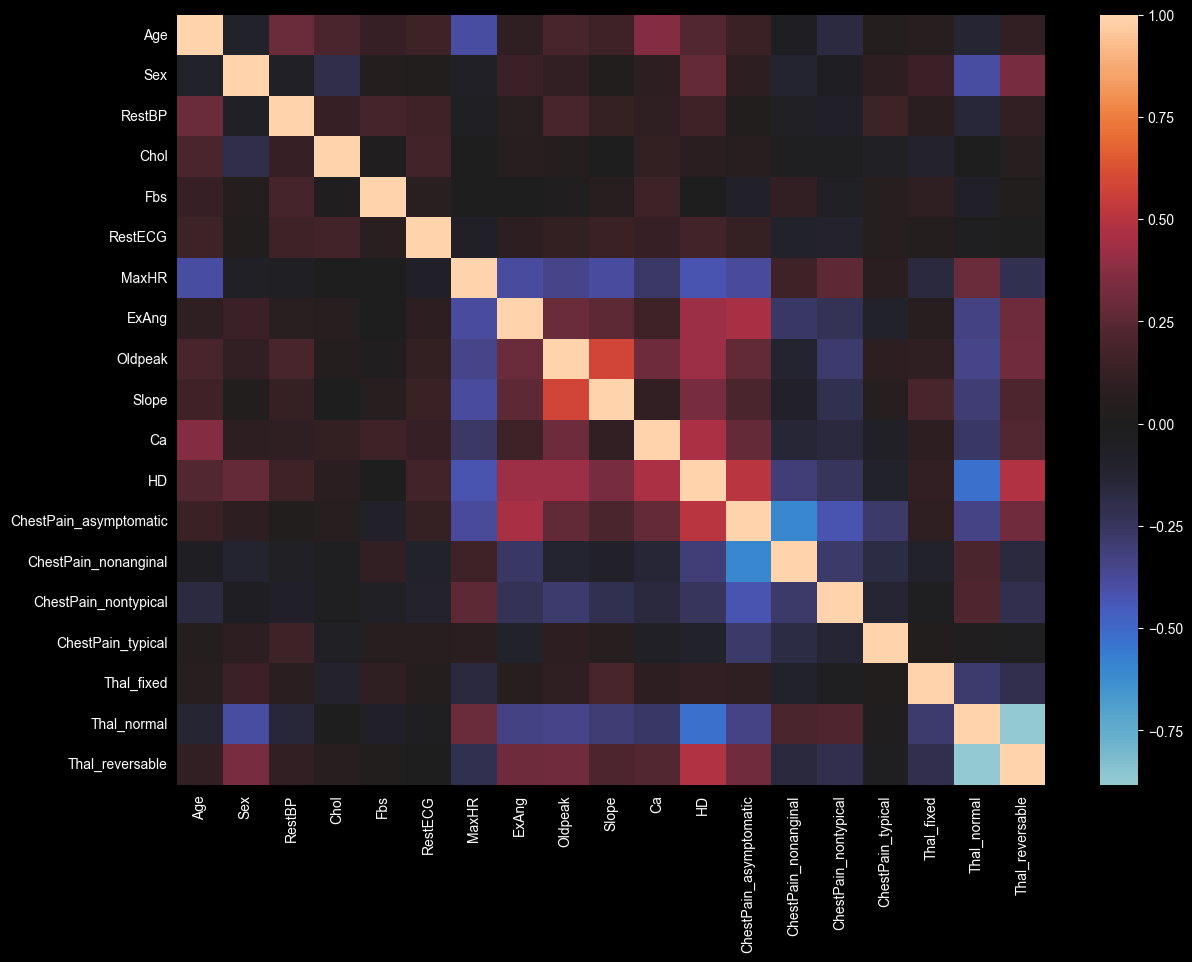

In [10]:
plt.figure(figsize=(14, 10))
sns.heatmap(heart.corr(numeric_only=True), center=0)
plt.show()

In [11]:
heart.corr().style.background_gradient(cmap="coolwarm")

,Age,Sex,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,HD,ChestPain_asymptomatic,ChestPain_nonanginal,ChestPain_nontypical,ChestPain_typical,Thal_fixed,Thal_normal,Thal_reversable
Age,1.000000,-0.092399,0.290476,0.202644,0.132062,0.149917,-0.394563,0.096489,0.197123,0.159405,0.362210,0.227075,0.137297,-0.043181,-0.163227,0.042571,0.059732,-0.130333,0.103792
Sex,-0.092399,1.000000,-0.066340,-0.198089,0.038850,0.033897,-0.060496,0.143581,0.106567,0.033345,0.091925,0.278467,0.085014,-0.115054,-0.041925,0.092497,0.145368,-0.390730,0.327671
RestBP,0.290476,-0.066340,1.000000,0.131536,0.180860,0.149242,-0.049108,0.066691,0.191243,0.121172,0.097954,0.153490,0.029082,-0.054825,-0.080820,0.149921,0.075211,-0.143474,0.109624
Chol,0.202644,-0.198089,0.131536,1.000000,0.012708,0.165046,-0.000075,0.059339,0.038596,-0.009215,0.115945,0.080285,0.064831,-0.023570,-0.017678,-0.057040,-0.099575,0.001379,0.047368
Fbs,0.132062,0.038850,0.180860,0.012708,1.000000,0.068831,-0.007842,-0.000893,0.008311,0.047819,0.152086,0.003167,-0.087329,0.106259,-0.053990,0.059785,0.096002,-0.072045,0.026522
RestECG,0.149917,0.033897,0.149242,0.165046,0.068831,1.000000,-0.072290,0.081874,0.113726,0.135141,0.129021,0.166343,0.118613,-0.088542,-0.098958,0.064395,0.043483,-0.023504,0.002695
MaxHR,-0.394563,-0.060496,-0.049108,-0.000075,-0.007842,-0.072290,1.000000,-0.384368,-0.347640,-0.389307,-0.268727,-0.423817,-0.377920,0.160943,0.256120,0.080420,-0.160679,0.286684,-0.213956
ExAng,0.096489,0.143581,0.066691,0.059339,-0.000893,0.081874,-0.384368,1.000000,0.289310,0.250572,0.148232,0.421355,0.454514,-0.257718,-0.232185,-0.094329,0.063827,-0.325755,0.301283
Oldpeak,0.197123,0.106567,0.191243,0.038596,0.008311,0.113726,-0.347640,0.289310,1.000000,0.579037,0.294452,0.424052,0.271036,-0.117376,-0.283033,0.083559,0.101819,-0.347874,0.305253
Slope,0.159405,0.033345,0.121172,-0.009215,0.047819,0.135141,-0.389307,0.250572,0.579037,1.000000,0.109761,0.333049,0.201156,-0.085393,-0.213606,0.064052,0.186386,-0.294494,0.209335


**Do there appear to be any patterns? (ungraded)**

Heart disease is most positively associated with the ChestPain_asymptomatic and Thal_reversable features, and most negatively associated with the ChestPain_nonanginal and Thal_normal features.

3. What is the minimum and maximum ages of the patients in the dataset? Assign this value to the variable `min_age` and `max_age`.

*Notes for Gradescope*:

1. Store the smallest and the largest value of `heart["Age"]` in `min_age` and `max_age`, as numbers, and print them.

In [12]:
# PROJECT7_TASK:age
# Define: min_age, max_age

# YOUR CODE HERE
min_age = heart["Age"].min()
max_age = heart["Age"].max()
print(f"Minimum age: {min_age}, Maximum age: {max_age}")

Minimum age: 29, Maximum age: 77


In [13]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_age(heart, min_age, max_age)

[PASS] age


True

4. Calculate the pairwise correlations between all the variables. Which predictor has the highest positive correlation with the response variable? Assign this to `highest_corr`. 

Hint: Your answer should be in the format `ColumnName_type` where the type is the result of one-hot encoding. 

*Notes for Gradescope*:

1. Store the predictor's exact column name in `highest_corr`, as a string, for example `"Thal_normal"` (this example isn't the answer).
2. Leave out `HD` itself: its correlation with itself is always 1.
3. Compute the name from the correlation matrix, for example from `heart.corr()`. Don't type it in: Gradescope runs this cell on different data.

In [14]:
# PROJECT7_TASK:corr
# Define: highest_corr

highest_corr = heart.corr(numeric_only=True)["HD"].drop("HD").idxmax()
highest_corr

'ChestPain_asymptomatic'

In [15]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_corr(heart, highest_corr)

[PASS] corr


True

6. Since we are interested in building a predictive model, it is good practice to split the data into training and testing sets. Using `sklearn.model_selection.train_test_split`, divide the data into these sets using a 80/20 split with a `random_state=42`. These training and testing sets will be used for all the following parts.

*Notes for Gradescope*:

1. Store every column of `heart` except `HD` in `X` (18 predictors, in the same order), and the `HD` column in `y`.
2. Split with `train_test_split(X, y, test_size=0.2, random_state=42)` and unpack the result as `X_train, X_test, y_train, y_test`, in that order.
3. On the real data `X_train` is 237 × 18 and `X_test` is 60 × 18.

In [16]:
# PROJECT7_TASK:split
# Define: X, y, X_train, X_test, y_train, y_test

# YOUR CODE HERE
X = heart.drop(columns=["HD"])
y = heart["HD"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_split(heart, X_train, X_test, y_train, y_test)

[PASS] split


True

## 7. Part A: Decision Tree

1. Using all predictor variables, train a <u>base</u> classification tree to predict the response variable. Use `sklearn.tree.DecisionTreeClassifier` and set `random_state=42`. 

*Hint*: here is the link for the documentation of [sklearn.tree.DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

*Notes for Gradescope*:

1. Store the tree in `clf`: `DecisionTreeClassifier(random_state=42)` with every other setting at its default, fitted on `X_train` and `y_train`.
2. Store its predictions for `X_test` in `y_pred`; question 3 uses them.

In [18]:
# PROJECT7_TASK:dt
# Define: clf, y_pred

# YOUR CODE HERE
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)


In [19]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_dt(clf, X_train)

[PASS] dt


True

2. Plot the decision tree using the `Graphviz` package. Do you notice anything interesting?

*Hint*: To do this, click on the little computer button on the Codio sidebar that says "Open Terminal." Once you are in the terminal, copy and paste the following and hit enter:

```
pip install --upgrade pip --user
pip install pydotplus --user
pip install graphviz --user
pip install ipython --user
sudo apt-get install graphviz
```

After, save your work and then click kernel -> 'restart and run all'. You should be able to use `Graphviz` package now!

If any of the above commands fails, please replace 'pip install' with 'sudo apt-get install `<package-name>`'. If you are having trouble with the installation, please post on Piazza or visit office hours.
    
To pass the test, your img should be of type `<class 'IPython.core.display.Image'>`.

*Notes for Gradescope*:

1. Store the picture in `img`, built in three steps: `dot_data = tree.export_graphviz(clf, out_file=None, ...)`, then `graph = pydotplus.graph_from_dot_data(dot_data)`, then `img = Image(graph.create_png())`.
2. You may add options such as `feature_names=list(X_train.columns)` and `filled=True`, but not `special_characters=True`: `pydotplus` can't read the labels it produces.
3. Gradescope doesn't have Graphviz, so this is the only way of drawing the tree it accepts. If you want to try `plot_tree` or `graphviz.Source`, do it in an ungraded cell.
4. Skip the Codio steps above; the install cell under *Getting Set Up* replaces them. On your own computer you also need the Graphviz program (see that cell).

In [20]:
# PROJECT7_TASK:image
# Define: img

# YOUR CODE HERE
dot_data = tree.export_graphviz(
    clf,
    out_file=None,
    feature_names=list(X_train.columns),
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
)
graph = pydotplus.graph_from_dot_data(dot_data)
img = Image(graph.create_png())

In [21]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_image(img)

[PASS] image


True

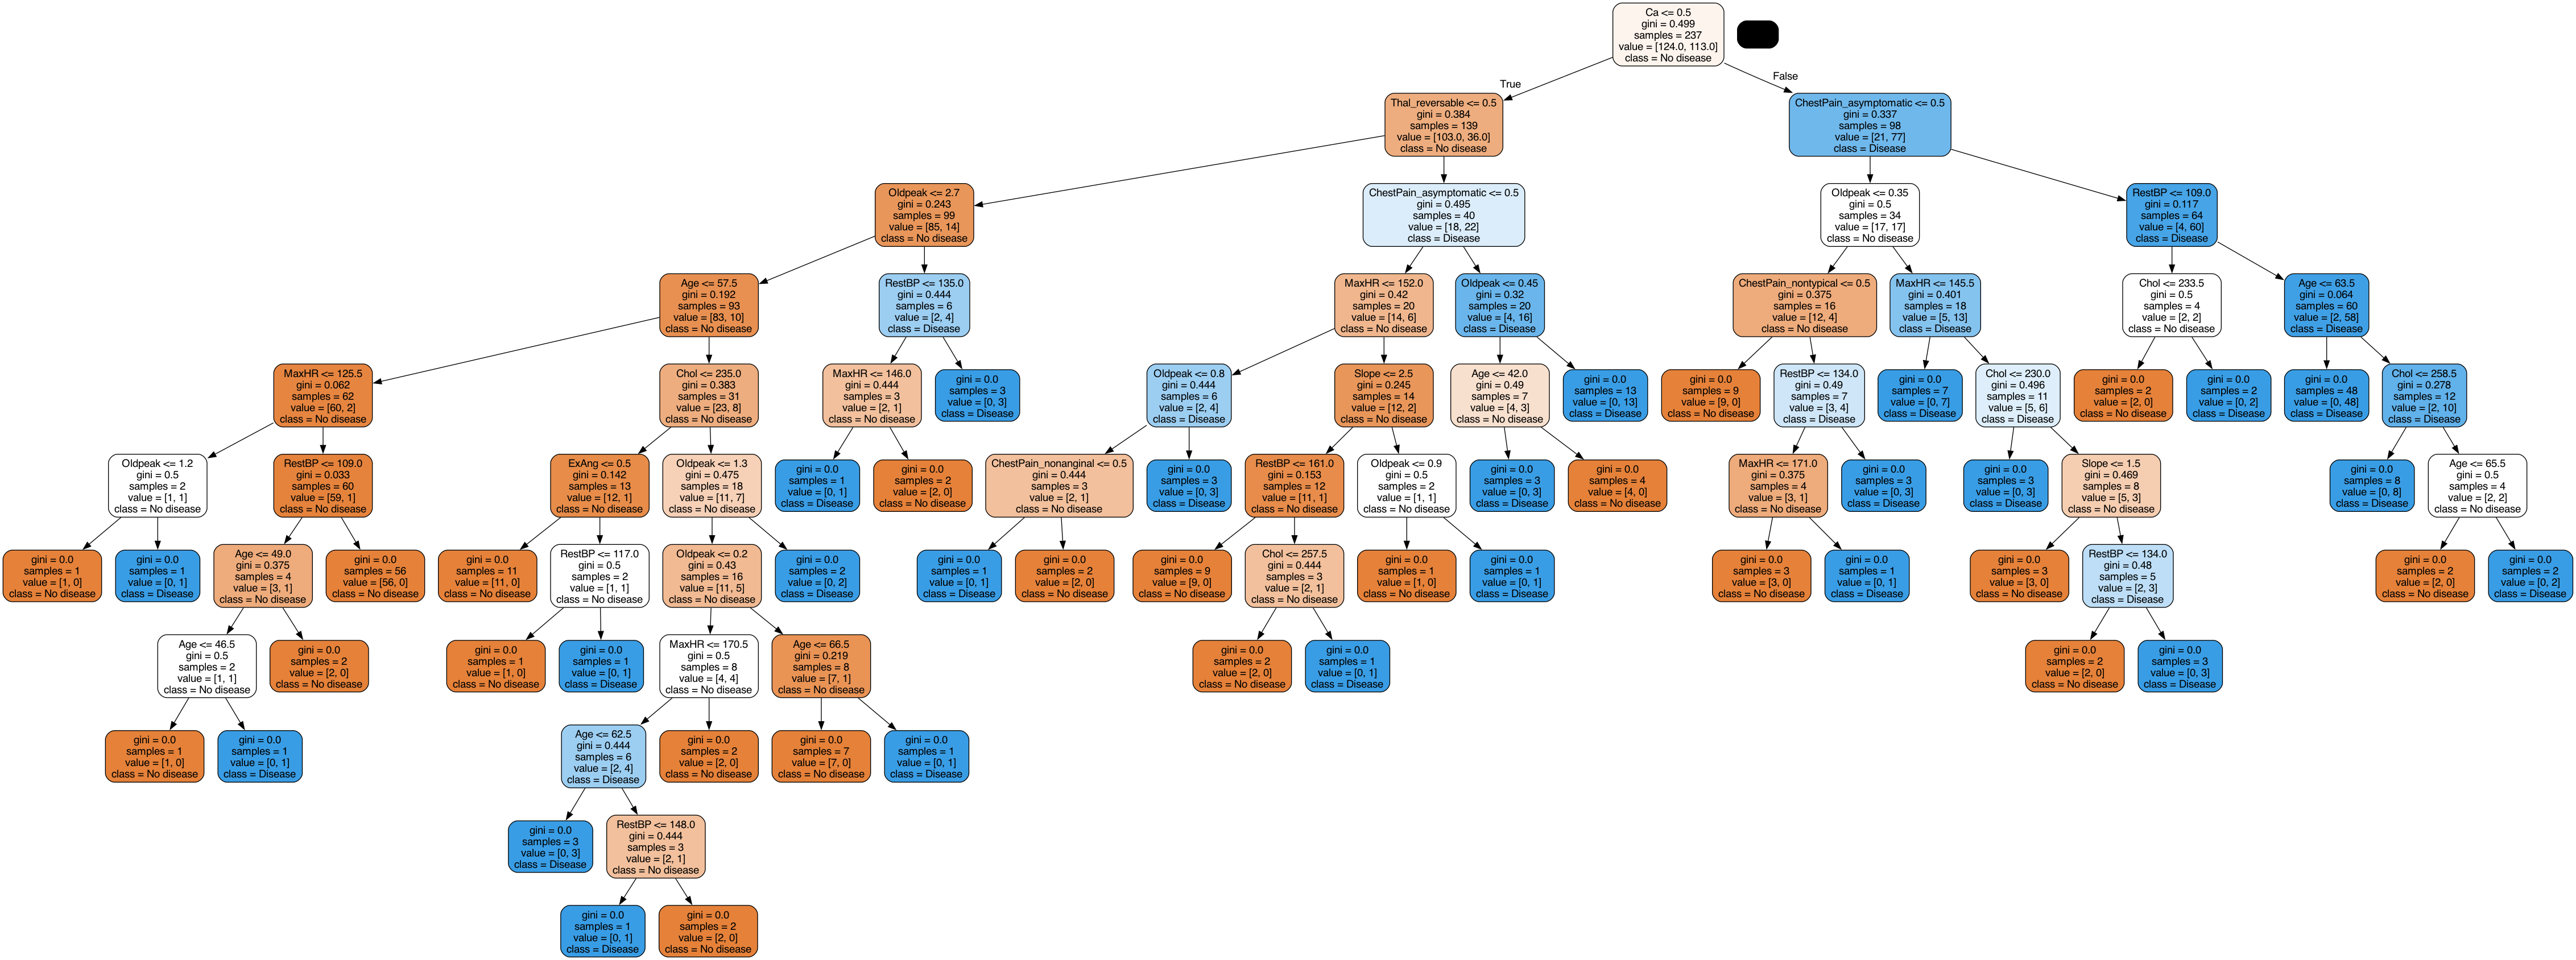

In [22]:
img

In [23]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_image(img)

[PASS] image


True

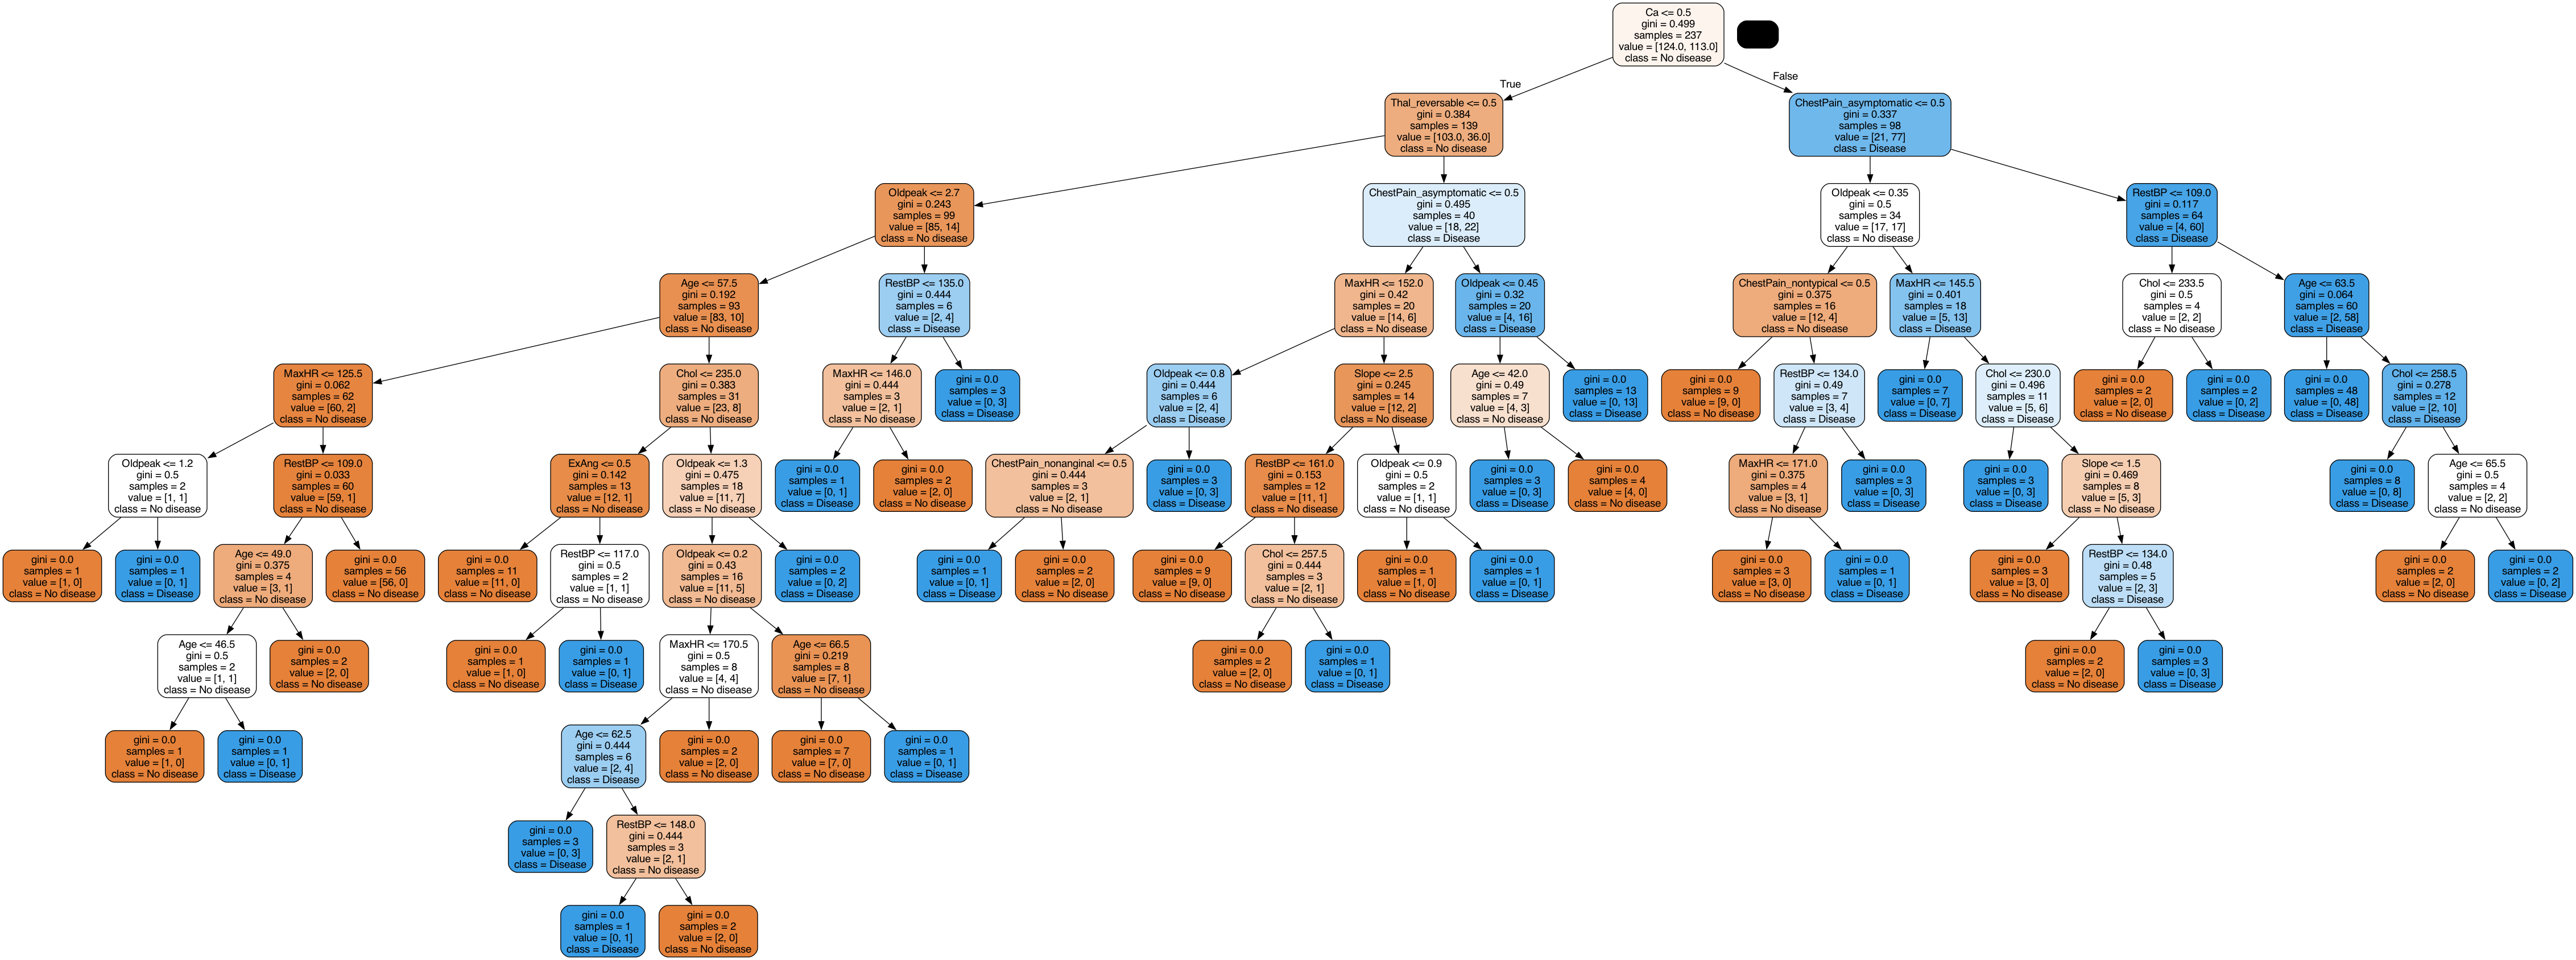

In [24]:
img

In [25]:
with open("output_image.png", "wb") as f:
    f.write(img.data)

**Do you notice anything interesting? (ungraded)**

The tree makes a sequence of threshold-based decisions, so it is possible to follow a path from the root to a predicted class.

3. Evaluate your base model on the test set by calculating the precision, recall and accuracy. Assign these values to `dt_precision`, `dt_recall` and `dt_accuracy` respectively. Name your model `dt`. **Be sure to print your precision, recall, and accuracy for use later** 

*Hint*: A useful resource if you need a refresher of these terms is [here](https://en.wikipedia.org/wiki/Precision_and_recall).

*Notes for Gradescope*:

1. Store the test-set metrics of `clf` in `dt_precision`, `dt_recall` and `dt_accuracy`, using `precision_score`, `recall_score` and `accuracy_score`, and print them.
2. Pass the true labels first, as in `precision_score(y_test, y_pred)`. Swapping the two arguments swaps precision and recall.
3. The question says to name your model `dt`; you don't need to. Gradescope uses `clf` from question 1.

In [26]:
# PROJECT7_TASK:dt_score
# Define: dt_precision, dt_recall, dt_accuracy

# YOUR CODE HERE
dt_precision = precision_score(y_test, y_pred)
dt_recall = recall_score(y_test, y_pred)
dt_accuracy = accuracy_score(y_test, y_pred)
print(f"Precision: {dt_precision}")
print(f"Recall: {dt_recall}")
print(f"Accuracy: {dt_accuracy}")

Precision: 0.7241379310344828
Recall: 0.875
Accuracy: 0.8166666666666667


In [27]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_dt_score(clf, X_test, y_test, dt_precision, dt_recall, dt_accuracy)

[PASS] dt_score


True

4a. Which hyperparameter should we tune when building a decision tree? Select all that applies:

A. Tree depth

B. Number of estimators

C. Number of output classes

D. Percent of samples trained

*Notes for Gradescope*:

1. Store your answer in `answers` as a list of uppercase letters, for example `["B"]` or `["B", "D"]` (these examples aren't the answer).
2. The public check only looks at the format of your answer, not whether it's right.

In [28]:
# PROJECT7_TASK:dt_tune
# Define: answers, e.g. ["B"] or ["B", "D"]

answers = ["A"]

In [29]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_dt_tune(answers)

[PASS] dt_tune


True

4b. Tune the hyperparameter you selected in the above question and evaluate this tuned model by calculating the precision, recall and accuracy on the test set. Assign these calculated values to `dt_tuned_precision`, `dt_tuned_recall` and `dt_tuned_accuracy` respectively. **Be sure to print your precision, recall, and accuracy for use later**

*Hint*: 
1. Refer to the documentation to determine what can be tuned. 
2. For each tuned parameter, search through range between 3 and 20 (inclusive: `np.arange(3, 21)`) to find the best performing parameters. 
3. To tune hyperparameters, use GridSearchCV with `cv=10`. This will apply KFold on your training set so you split your training set into a smaller training set and a "validation" set, which GridSearchCV will use to pick the best parameters. If you do not specify `cv=10`, GridSearchCV will by default use 5-fold cross validation. Read more about train/validation/test sets [here](https://blog.roboflow.com/train-test-split/). 

*Notes for Gradescope*:

1. Store the search in `grid_search_cv_dt`: a `GridSearchCV` with `DecisionTreeClassifier(random_state=42)`, the grid `{"max_depth": np.arange(3, 21)}` and `cv=10`, fitted on `X_train` and `y_train`.
2. Create the tree inside `GridSearchCV`, as in note 1. Gradescope runs this cell by itself, and `clf` from question 1 doesn't exist there.
3. Write `cv=10` as the number 10, not as a `KFold` object, and leave `scoring` at its default (accuracy).
4. Compute `dt_tuned_precision`, `dt_tuned_recall` and `dt_tuned_accuracy` from `grid_search_cv_dt.predict(X_test)`. Don't refit a tree with a depth you typed in; on Gradescope's data the best depth is different.
5. Print `grid_search_cv_dt.best_params_` and the three metrics.

In [30]:
# PROJECT7_TASK:dt_tuned
# Define: grid_search_cv_dt, dt_tuned_precision, dt_tuned_recall, dt_tuned_accuracy

# YOUR CODE HERE

grid_search_cv_dt = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid={"max_depth": np.arange(3, 21)},
    cv=10,
)
grid_search_cv_dt.fit(X_train, y_train)

dt_tuned_precision = precision_score(y_test, grid_search_cv_dt.predict(X_test))
dt_tuned_recall = recall_score(y_test, grid_search_cv_dt.predict(X_test))
dt_tuned_accuracy = accuracy_score(y_test, grid_search_cv_dt.predict(X_test))

print(f"Best parameters: {grid_search_cv_dt.best_params_}")
print(f"Tuned Precision: {dt_tuned_precision}")
print(f"Tuned Recall: {dt_tuned_recall}")
print(f"Tuned Accuracy: {dt_tuned_accuracy}")


Best parameters: {'max_depth': np.int64(4)}
Tuned Precision: 0.6666666666666666
Tuned Recall: 0.8333333333333334
Tuned Accuracy: 0.7666666666666667


In [31]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_dt_tuned(
    grid_search_cv_dt, X_test, y_test,
    dt_tuned_precision, dt_tuned_recall, dt_tuned_accuracy,
)

[PASS] dt_tuned


True

## 8. Part B: Bagging

1. Using all predictor variables, train a base model to predict the response variable. Use `sklearn.ensemble.BaggingClassifier` and set `random_state=42`. Name your model as `bag`.

*Notes for Gradescope*:

1. Store the model in `bag`: `BaggingClassifier(random_state=42)` with every other setting at its default, fitted on `X_train` and `y_train`.
2. Don't pass an `estimator`: the default base model is a decision tree, and the default number of trees is 10.

In [32]:
# PROJECT7_TASK:bag
# Define: bag

# YOUR CODE HERE
bag = BaggingClassifier(random_state=42)
bag.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",10
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",None
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",True
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


In [33]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_bag(bag, X_train, y_train)

[PASS] bag


True

2. Evaluate your base model on the test set by calculating the precision, recall and accuracy. Assign these values to `bag_precision`, `bag_recall`  and `bag_accuracy` respectively. **Be sure to print your precision, recall, and accuracy for use later**

*Notes for Gradescope*:

1. Store the test-set metrics of `bag` in `bag_precision`, `bag_recall` and `bag_accuracy`, and print them.
2. Compute `bag`'s predictions in this cell. In your notebook `y_pred` still holds the decision tree's predictions, and on Gradescope it doesn't exist in this cell.

In [34]:
# PROJECT7_TASK:bag_score
# Define: bag_precision, bag_recall, bag_accuracy

# YOUR CODE HERE
bag_precision = precision_score(y_test, bag.predict(X_test))
bag_recall = recall_score(y_test, bag.predict(X_test))
bag_accuracy = accuracy_score(y_test, bag.predict(X_test))
print(f"Bagging Precision: {bag_precision}")
print(f"Bagging Recall: {bag_recall}")
print(f"Bagging Accuracy: {bag_accuracy}")

Bagging Precision: 0.8636363636363636
Bagging Recall: 0.7916666666666666
Bagging Accuracy: 0.8666666666666667


In [35]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_bag_score(bag, X_test, y_test, bag_precision, bag_recall, bag_accuracy)

[PASS] bag_score


True

In [36]:
# Ungraded: confusion matrix of the base bagging model
# (rows: true class 0, 1; columns: predicted class 0, 1)
confusion_matrix(y_test, bag.predict(X_test))

array([[33,  3],
       [ 5, 19]])

3. Do <b>not</b> modify `base_classifier`. Tune the `n_estimators` hyperparameter of your model and evaluate this tuned model by calculating the precision, recall, and accuracy on the test set. Assign these calculated values to `bag_tuned_precision`, `bag_tuned_recall` and `bag_tuned_accuracy`  respectively. **Be sure to print your precision, recall, and accuracy for use later.** Store your best performing estimators to `bag_best_param` as a dictionary ('tuned estimator' : number). *Hint*: Set the searching space to all integers between range 10 and 49 (inclusive: `np.arange(10, 50)`). To tune hyperparameters, use GridSearchCV with `cv=10`. This will apply KFold on your training set so you split your training set into a smaller training set and a "validation" set, which GridSearchCV will use to pick the best parameters. If you do not specify `cv=10`, GridSearchCV will by default use 5-fold cross validation. Read more about train/validation/test sets [here](https://blog.roboflow.com/train-test-split/). 

*Notes for Gradescope*:

1. Store the search in `grid_search_cv_bag`: a `GridSearchCV` with `BaggingClassifier(random_state=42)`, the grid `{"n_estimators": np.arange(10, 50)}` and `cv=10` (the number 10), fitted on `X_train` and `y_train`.
2. Create the model inside `GridSearchCV`, as in note 1. Gradescope runs this cell by itself, and `bag` from question 1 doesn't exist there.
3. "Do not modify `base_classifier`" means: don't pass an `estimator` (scikit-learn's current name for the base classifier).
4. Compute `bag_tuned_precision`, `bag_tuned_recall` and `bag_tuned_accuracy` from `grid_search_cv_bag.predict(X_test)`.
5. Store `grid_search_cv_bag.best_params_` in `bag_best_param`, in this same cell. It's a dictionary such as `{"n_estimators": 23}`, and Gradescope grades it as a separate point.
6. Print `bag_best_param` and the three metrics.

In [37]:
# PROJECT7_TASK:bag_tuned
# Define: grid_search_cv_bag, bag_tuned_precision, bag_tuned_recall, bag_tuned_accuracy, bag_best_param

# YOUR CODE HERE
grid_search_cv_bag = GridSearchCV(
    BaggingClassifier(random_state=42),
    param_grid={"n_estimators": np.arange(10, 50)},
    cv=10,
)
grid_search_cv_bag.fit(X_train, y_train)
bag_tuned_precision = precision_score(y_test, grid_search_cv_bag.predict(X_test))
bag_tuned_recall = recall_score(y_test, grid_search_cv_bag.predict(X_test))
bag_tuned_accuracy = accuracy_score(y_test, grid_search_cv_bag.predict(X_test))
bag_best_param = grid_search_cv_bag.best_params_
print(f"Best parameters: {bag_best_param}")
print(f"Tuned Bagging Precision: {bag_tuned_precision}")
print(f"Tuned Bagging Recall: {bag_tuned_recall}")
print(f"Tuned Bagging Accuracy: {bag_tuned_accuracy}")

Best parameters: {'n_estimators': np.int64(19)}
Tuned Bagging Precision: 0.8333333333333334
Tuned Bagging Recall: 0.8333333333333334
Tuned Bagging Accuracy: 0.8666666666666667


In [38]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_bag_tuned(
    grid_search_cv_bag, X_test, y_test,
    bag_tuned_precision, bag_tuned_recall, bag_tuned_accuracy,
)

[PASS] bag_tuned


True

In [39]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_bag_best(bag_best_param, grid_search_cv_bag)

[PASS] bag_best


True

## 9. Part C: Random Forest

1. Using all predictor variables, train a base random forest to predict the response variable. Use `sklearn.ensemble.RandomForestClassifier` and set `random_state=42`. Name your model `rf`.

*Notes for Gradescope*:

1. Store the forest in `rf`: `RandomForestClassifier(random_state=42)` with every other setting at its default (100 trees), fitted on `X_train` and `y_train`.

In [40]:
# PROJECT7_TASK:rf
# Define: rf

# YOUR CODE HERE
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [41]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_rf(rf)

[PASS] rf


True

2. Evaluate your base model on the test set by calculating the precision, recall and accuracy. Assign these values to `rf_precision`, `rf_recall` and `rf_accuracy` respectively. **Be sure to print your precision, recall, and accuracy for use later**

*Notes for Gradescope*:

1. Store the test-set metrics of `rf` in `rf_precision`, `rf_recall` and `rf_accuracy`, and print them.
2. Compute `rf`'s predictions in this cell. In your notebook `y_pred` still holds the decision tree's predictions.

In [42]:
# PROJECT7_TASK:rf_score
# Define: rf_precision, rf_recall, rf_accuracy

# YOUR CODE HERE
rf_precision = precision_score(y_test, rf.predict(X_test))
rf_recall = recall_score(y_test, rf.predict(X_test))
rf_accuracy = accuracy_score(y_test, rf.predict(X_test))
print(f"Random Forest Precision: {rf_precision}")
print(f"Random Forest Recall: {rf_recall}")
print(f"Random Forest Accuracy: {rf_accuracy}")

Random Forest Precision: 0.84
Random Forest Recall: 0.875
Random Forest Accuracy: 0.8833333333333333


In [43]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_rf_score(rf, X_test, y_test, rf_precision, rf_recall, rf_accuracy)

[PASS] rf_score


True

3. Tune the hyperparameters of your model and evaluate this tuned model by calculating the precision, recall and accuracy on the test set. Assign these calculated values to `rf_tuned_precision`, `rf_tuned_recall` and `rf_tuned_accuracy` respectively. Store your best-performing parameters to `rf_tuned`. **Be sure to print your precision, recall, and accuracy for use later.** Also don't forget to set `random_state=42`. 

*Hint*: 
1. In this question, we would like to tune only the parameters determining the depth of a tree and the number of trees. But beware that you can also adjust the maximum number of features considered for each tree(max_features), the minimum number of data points placed in a node before the node is split(min_samples_split), the minimum number of data points allowed in a leaf node(min_samples_leaf), and bootstrap option. Refer to [sklearn.RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) for a complete list.
2. In this question, your parameter search space is (3,20) for tree depth, (10,29) for number of trees, both inclusive (`np.arange(3, 21)` and `np.arange(10, 30)`).
3. To tune hyperparameters, use GridSearchCV with `cv=10`. This will apply KFold on your training set so you split your training set into a smaller training set and a "validation" set, which GridSearchCV will use to pick the best parameters. If you do not specify `cv=10`, GridSearchCV will by default use 5-fold cross validation. Read more about train/validation/test sets [here](https://blog.roboflow.com/train-test-split/). 

*Notes for Gradescope*:

1. Store the search in `grid_search_cv_rf`: a `GridSearchCV` with `RandomForestClassifier(random_state=42)`, the grid `{"max_depth": np.arange(3, 21), "n_estimators": np.arange(10, 30)}` and `cv=10` (the number 10), fitted on `X_train` and `y_train`. Leave every other setting at its default.
2. Create the forest inside `GridSearchCV`, as in note 1. Gradescope runs this cell by itself, and `rf` from question 1 doesn't exist there.
3. Compute `rf_tuned_precision`, `rf_tuned_recall` and `rf_tuned_accuracy` from `grid_search_cv_rf.predict(X_test)`. Don't refit a forest with values you typed in.
4. Print `grid_search_cv_rf.best_params_` and the three metrics.
5. The search fits 3,600 forests (360 combinations × 10 folds) and takes a few minutes. Adding `n_jobs=-1` to `GridSearchCV` uses all your CPU cores and gives the same result.
6. Gradescope grades this cell together with the next one, which stores `rf_tuned`. Finish both, or you lose both points.

In [44]:
# PROJECT7_TASK:rf_tuned
# Define: grid_search_cv_rf, rf_tuned_precision, rf_tuned_recall, rf_tuned_accuracy

# YOUR CODE HERE
grid_search_cv_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid={
        "max_depth": np.arange(3, 21),
        "n_estimators": np.arange(10, 30),
    },
    cv=10,
)
grid_search_cv_rf.fit(X_train, y_train)
rf_tuned_precision = precision_score(y_test, grid_search_cv_rf.predict(X_test))
rf_tuned_recall = recall_score(y_test, grid_search_cv_rf.predict(X_test))
rf_tuned_accuracy = accuracy_score(y_test, grid_search_cv_rf.predict(X_test))
print(f"Best parameters: {grid_search_cv_rf.best_params_}")
print(f"Tuned Random Forest Precision: {rf_tuned_precision}")
print(f"Tuned Random Forest Recall: {rf_tuned_recall}")
print(f"Tuned Random Forest Accuracy: {rf_tuned_accuracy}")

Best parameters: {'max_depth': np.int64(4), 'n_estimators': np.int64(20)}
Tuned Random Forest Precision: 0.8695652173913043
Tuned Random Forest Recall: 0.8333333333333334
Tuned Random Forest Accuracy: 0.8833333333333333


In [45]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_rf_tuned(
    grid_search_cv_rf, X_test, y_test,
    rf_tuned_precision, rf_tuned_recall, rf_tuned_accuracy,
)

[PASS] rf_tuned


True

*Notes for Gradescope*:

1. Store `grid_search_cv_rf.best_params_` in `rf_tuned`: a dictionary with the keys `max_depth` and `n_estimators`.

In [46]:
# PROJECT7_TASK:rf_tuned_params
# Define: rf_tuned

# YOUR CODE HERE
rf_tuned = grid_search_cv_rf.best_params_

In [47]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_rf_tuned_params(rf_tuned, grid_search_cv_rf)

[PASS] rf_tuned_params


True

**All test-set metrics side by side (ungraded).** The next cell collects your
results in one table. Use it for questions 10 and 11.

In [48]:
# Ungraded: all test-set metrics side by side
comparison = pd.DataFrame(
    {
        "base precision": [dt_precision, bag_precision, rf_precision],
        "base recall": [dt_recall, bag_recall, rf_recall],
        "base accuracy": [dt_accuracy, bag_accuracy, rf_accuracy],
        "tuned precision": [dt_tuned_precision, bag_tuned_precision, rf_tuned_precision],
        "tuned recall": [dt_tuned_recall, bag_tuned_recall, rf_tuned_recall],
        "tuned accuracy": [dt_tuned_accuracy, bag_tuned_accuracy, rf_tuned_accuracy],
    },
    index=["A. Decision Tree", "B. Bagging", "C. Random Forest"],
)
comparison

,base precision,base recall,base accuracy,tuned precision,tuned recall,tuned accuracy
A. Decision Tree,0.724138,0.875000,0.816667,0.666667,0.833333,0.766667
B. Bagging,0.863636,0.791667,0.866667,0.833333,0.833333,0.866667
C. Random Forest,0.840000,0.875000,0.883333,0.869565,0.833333,0.883333


10. Of the 3 base models that you trained, which model achieved the highest test accuracy? 

A. Decision Tree

B. Bagging

C. Random Forest

*Notes for Gradescope*:

1. Store your answer in `choice` as a list with one uppercase letter, for example `["A"]`.
2. The public check only looks at the format of your answer, not whether it's right.

In [49]:
# PROJECT7_TASK:base_choice
# Define: choice, e.g. ["A"]

choice = ["C"]

In [50]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_base_choice(choice)

[PASS] base_choice


True

11. Of the 3 models in which you tuned the parameters, which model achieved the highest test accuracy? 

A. Decision Tree

B. Bagging

C. Random Forest

*Notes for Gradescope*:

1. Store your answer in `choice` as a list with one uppercase letter, for example `["A"]`.
2. Question 10 also uses the name `choice`. That's fine: Gradescope runs each cell by itself.
3. The public check only looks at the format of your answer, not whether it's right.

In [51]:
# PROJECT7_TASK:tuned_choice
# Define: choice, e.g. ["A"]

choice = ["C"]

In [52]:
# In[ ]: end of the graded cell above, for Gradescope. Keep this line.
public_checks.check_tuned_choice(choice)

[PASS] tuned_choice


True

12. *Food for thought (ungraded but interesting to think about)*: In this project, we asked you to pick the model with the highest test accuracy. For this task, do you think that accuracy is the best metric to use, or would precision, recall or even the F1-score be better?

in this case, recall may matter because a false negative could delay follow-up. Precision also matters because false positives can lead to unnecessary tests.


## Submitting to Gradescope

**Step 1: public-check summary.** Every check above should say `[PASS]`.

In [53]:
public_checks.show_public_check_summary()

Public checks passed: 20/20
Gradescope reruns each graded cell on hidden data and also grades the three multiple-choice answers, which these checks don't.


**Step 2: convert the notebook to `project7_submission.py`.**

- First, save the notebook. On Colab, also download it: **File → Download →
  Download .ipynb**.
- Run the next cell. It defines `download_notebook_as_py()`.
- In the cell after it, delete the `#` in front of `download_notebook_as_py()`
  and run it. It writes `project7_submission.py`, checks that the file is valid
  Python and, on Colab, downloads it. If Colab can't find your notebook, a file
  picker opens: select the `.ipynb` you downloaded.

If you renamed this notebook, pass the new name, for example
`download_notebook_as_py("my_notebook.ipynb")`.

In [54]:
from pathlib import Path
import subprocess
import sys


def download_notebook_as_py(
    ipynb_path="project7_student.ipynb",
    output_name="project7_submission.py",
):
    """
    Convert the completed notebook to a .py file, check that the result is
    valid Python, and download it when running in Google Colab.
    """
    ipynb_path = Path(ipynb_path)

    if not ipynb_path.exists():
        try:
            from google.colab import files

            print(
                f"Could not find {ipynb_path.name} in the runtime.\n"
                "Select your saved .ipynb notebook in the file picker."
            )
            uploaded = files.upload()
            notebook_names = [
                name for name in uploaded if name.lower().endswith(".ipynb")
            ]
            if len(notebook_names) != 1:
                raise ValueError("Please upload exactly one .ipynb notebook.")
            ipynb_path = Path(notebook_names[0])

        except ImportError:
            raise FileNotFoundError(f"Could not find notebook: {ipynb_path}")

    if ipynb_path.suffix.lower() != ".ipynb":
        raise ValueError("The input file must be a .ipynb file.")

    if not output_name.lower().endswith(".py"):
        output_name += ".py"
    output_path = Path(output_name)

    subprocess.run(
        [
            sys.executable, "-m", "jupyter", "nbconvert",
            "--to", "python",
            str(ipynb_path),
            "--output", output_path.stem,
            "--output-dir", str(output_path.parent),
        ],
        check=True,
    )

    source = output_path.read_text(encoding="utf-8")
    compile(source, str(output_path), "exec")

    print(f"Created and verified: {output_path.resolve()}")
    print("Upload this .py file to Gradescope.")

    try:
        from google.colab import files
        files.download(str(output_path))
    except ImportError:
        print("Not running in Google Colab; the file remains on disk.")

    return str(output_path)

In [55]:
download_notebook_as_py()

[NbConvertApp] Converting notebook project7_student.ipynb to python
[NbConvertApp] ERROR | Notebook JSON is invalid: Additional properties are not allowed ('jetTransient' was unexpected)

Failed validating 'additionalProperties' in display_data:

On instance['cells'][19]['outputs'][0]:
{'data': {'image/png': 'iVBORw0KGgoAAAANSUhEUgAABKgAAAPCCAYAAABcFeCXAAAAOnRFWHRTb2Z0d2Fy...',
          'text/plain': '<Figure size 1400x1000 with 2 Axes>'},
 'jetTransient': {'display_id': None},
 'metadata': {},
 'output_type': 'display_data'}


Created and verified: /Users/fuadhassan/Desktop/MSE-AI/ese-5410/homework/project_7/project7_submission.py
Upload this .py file to Gradescope.
Not running in Google Colab; the file remains on disk.


[NbConvertApp] Writing 40912 bytes to project7_submission.py


'project7_submission.py'

**Step 3: check the converted file.** This reads `project7_submission.py` the
way Gradescope does. If it reports problems, fix them in the notebook, save,
convert again and rerun this cell.

In [56]:
public_checks.check_submission_file("project7_submission.py")

[PASS] submission_file


True

**Step 4: upload.** Upload `project7_submission.py` to Gradescope, keeping that
file name. Upload only this one file: Gradescope never uses `public_checks.py`
or your `Heart.csv`, and if it gets two `.py` files and neither is named
`project7_submission.py`, it rejects the submission ("Multiple .py files were
submitted"). Each of the 20 tests shows its result; a failed test shows a
message saying what was wrong.